# Logistic Regression — Thyroid Classification

A linear model, used here as the baseline the other three have to beat.

Like the SVM it needs two things the tree models did not: **no missing values**, and **scaling**,
because the coefficients are only comparable if every feature is on the same scale. Both go
inside a pipeline so they are fitted on the training folds only.

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import FunctionTransformer, LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (average_precision_score, classification_report,
                             confusion_matrix, precision_recall_curve)

CSV = "../dataset/hypothyroid.csv"
FEATURES = ["age", "sex", "TSH", "TT4", "T4U", "FTI"]
TARGET = "binaryClass"
CLASS_NAMES = ["negative", "hypothyroid"]
RANDOM_STATE = 42

## Load and clean

In [2]:
# Same cleaning as thyroid.ipynb section 3.
df = pd.read_csv(CSV, na_values="?")[FEATURES + [TARGET]]

known = df["sex"].notna()
df.loc[known, "sex"] = LabelEncoder().fit_transform(df.loc[known, "sex"])
df["sex"] = df["sex"].astype(float)

# LabelEncoder puts "N" first, and "N" is the hypothyroid group, so flip it.
df[TARGET] = 1 - LabelEncoder().fit_transform(df[TARGET])

clean = df[~(df["age"] > 120)].drop_duplicates()
X = clean[FEATURES]
y = clean[TARGET]
print(f"{len(clean)} patients, {y.sum()} hypothyroid ({100 * y.mean():.2f}%)")
clean.head()

3658 patients, 291 hypothyroid (7.96%)


,age,sex,TSH,TT4,T4U,FTI,binaryClass
0,41.0,0.0,1.30,125.0,1.14,109.0,0
1,23.0,0.0,4.10,102.0,NaN,NaN,0
2,46.0,1.0,0.98,109.0,0.91,120.0,0
3,70.0,0.0,0.16,175.0,NaN,NaN,0
4,70.0,0.0,0.72,61.0,0.87,70.0,0


## The pipeline

`log1p(TSH)` is applied first. TSH is heavily skewed — it runs from 0 to 530 — and a linear
model fits a straight line through whatever scale it is given, so the raw column would let a
handful of very large values dominate the fit.

In [3]:
log_tsh = ColumnTransformer([("log", FunctionTransformer(np.log1p), ["TSH"])],
                            remainder="passthrough")


def logreg(use_log=True, **kwargs):
    steps = [log_tsh] if use_log else []
    steps += [
        SimpleImputer(strategy="median"),
        StandardScaler(),
        LogisticRegression(class_weight="balanced", max_iter=2000,
                           random_state=RANDOM_STATE, **kwargs),
    ]
    return make_pipeline(*steps)


def evaluate(model, label):
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
    )
    model.fit(X_tr, y_tr)
    p = model.predict_proba(X_te)[:, 1]
    pred = (p >= 0.5).astype(int)
    return {
        "model": label,
        "avg_precision": round(average_precision_score(y_te, p), 4),
        "recall": round(((pred == 1) & (y_te == 1)).sum() / (y_te == 1).sum(), 4),
        "missed": int(((pred == 0) & (y_te == 1)).sum()),
        "false_alarms": int(((pred == 1) & (y_te == 0)).sum()),
    }

## 1. Does the log transform help?

In [4]:
pd.DataFrame([
    evaluate(logreg(use_log=False), "raw TSH"),
    evaluate(logreg(), "log1p(TSH)"),
]).set_index("model")

,avg_precision,recall,missed,false_alarms
model,,,,
raw TSH,0.9091,0.8966,6,15
log1p(TSH),0.9221,0.9310,4,26


## 2. Regularisation strength

`C` controls how much the coefficients are allowed to grow. Smaller `C` means stronger
regularisation.

In [5]:
pd.DataFrame([
    evaluate(logreg(C=0.1), "C = 0.1"),
    evaluate(logreg(), "C = 1 (default)"),
    evaluate(logreg(C=10), "C = 10"),
]).set_index("model")

,avg_precision,recall,missed,false_alarms
model,,,,
C = 0.1,0.9236,0.9655,2,28
C = 1 (default),0.9221,0.9310,4,26
C = 10,0.9210,0.9483,3,26


## 3. Final model

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

model = logreg()
model.fit(X_train, y_train)
proba = model.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)

print(f"test average precision: {average_precision_score(y_test, proba):.4f}\n")
print(classification_report(y_test, pred, target_names=CLASS_NAMES, digits=4))
print("confusion matrix [rows = actual]")
print(confusion_matrix(y_test, pred))

test average precision: 0.9221

              precision    recall  f1-score   support

    negative     0.9939    0.9614    0.9774       674
 hypothyroid     0.6750    0.9310    0.7826        58

    accuracy                         0.9590       732
   macro avg     0.8344    0.9462    0.8800       732
weighted avg     0.9686    0.9590    0.9619       732

confusion matrix [rows = actual]
[[648  26]
 [  4  54]]


## 4. The coefficients

This is what a linear model gives that the others do not: one number per feature, showing both
direction and strength. The features were scaled first, so the sizes are comparable.

A positive coefficient pushes a patient towards hypothyroid, a negative one away.

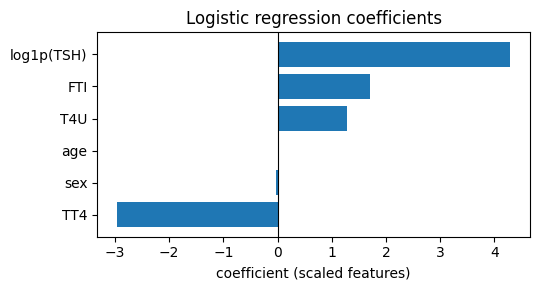

log1p(TSH)    4.2963
TT4          -2.9651
FTI           1.7081
T4U           1.2857
sex          -0.0256
age           0.0213
dtype: float64

In [7]:
names = ["log1p(TSH)"] + [c for c in FEATURES if c != "TSH"]
coef = pd.Series(model[-1].coef_[0], index=names).sort_values()

fig, ax = plt.subplots(figsize=(5.5, 3))
ax.barh(coef.index, coef.values)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("coefficient (scaled features)")
ax.set_title("Logistic regression coefficients")
plt.tight_layout()
plt.show()

coef.sort_values(key=abs, ascending=False).round(4)

TSH is positive and by far the largest, TT4 is negative — exactly the clinical pattern, and the
same ordering the random forest's permutation importance found. `age` and `sex` sit near zero.

One caveat: `FTI` is `TT4 / T4U`, so those three columns are not independent. When features are
correlated, a linear model splits the effect between them however it likes, and individual
coefficients stop being reliable on their own.

## 5. Precision-recall curve

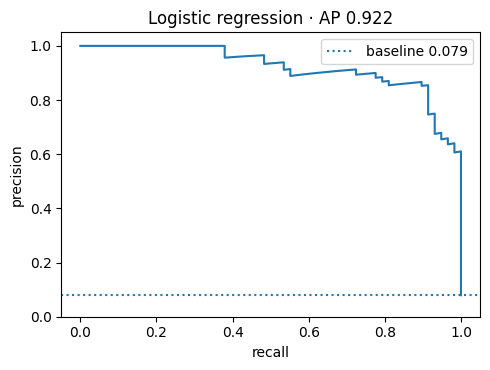

In [8]:
prec, rec, _ = precision_recall_curve(y_test, proba)

fig, ax = plt.subplots(figsize=(5, 3.8))
ax.plot(rec, prec)
ax.axhline(y_test.mean(), linestyle=":", label=f"baseline {y_test.mean():.3f}")
ax.set_xlabel("recall")
ax.set_ylabel("precision")
ax.set_title(f"Logistic regression · AP {average_precision_score(y_test, proba):.3f}")
ax.set_ylim(0, 1.05)
ax.legend()
plt.tight_layout()
plt.show()

## 6. Threshold sweep

In [9]:
pd.DataFrame([
    {"threshold": t,
     "recall": round(((proba >= t) & (y_test == 1)).sum() / (y_test == 1).sum(), 4),
     "missed": int(((proba < t) & (y_test == 1)).sum()),
     "false_alarms": int(((proba >= t) & (y_test == 0)).sum())}
    for t in [0.1, 0.2, 0.3, 0.5, 0.7]
]).set_index("threshold")

,recall,missed,false_alarms
threshold,,,
0.1,1.0000,0,81
0.2,1.0000,0,55
0.3,1.0000,0,41
0.5,0.9310,4,26
0.7,0.8966,6,8
